# 3. What explains burden? (RQ2 and RQ3)

OLS first, with diagnostics; then Lagrange Multiplier tests and likelihood ratio tests to choose
among the spatial error, spatial lag, and spatial Durbin models. The cost model (log average energy
bill) separates the cost side of burden from the income side. Script: `scripts/05_models.py`.

_Part of the Chicago Energy Burden project (James Rocco Quantitative Data Research Scholarship, Lake Forest College). Run the pipeline scripts first, or read the executed copy on GitHub._

In [1]:
import json, warnings
import numpy as np, pandas as pd, geopandas as gpd
from IPython.display import Image, Markdown, display
from ceb import config
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
T, F = config.TABLES, config.FIGURES
gdf = gpd.read_file(config.PROCESSED / "chicago_tracts.gpkg")
sample = gdf[gdf["in_main_sample"].astype(bool)].reset_index(drop=True)
print(f"{len(gdf)} tracts mostly inside Chicago; {len(sample)} in the analysis sample")

782 tracts mostly inside Chicago; 768 in the analysis sample


In [2]:
from ceb import geo, models
w = geo.weights(sample, "queen")
ols, table, diag = models.ols(sample, "burden_pct", w)
display(table[["term", "coef", "se", "p", "se_robust", "p_robust"]].round(4))
pd.Series({k: diag[k] for k in ["adj_r2", "breusch_pagan_p", "moran_resid_I", "moran_resid_p",
                                "lm_lag_p", "lm_error_p", "rlm_lag_p", "rlm_error_p"]}).round(4)

  note: 1 tract(s) with no touching neighbor ['17043840000']; linked to nearest tract


,term,coef,se,p,se_robust,p_robust
0,CONSTANT,25.0867,1.1351,0.0000,1.5840,0.0000
1,ln_income,-1.9570,0.0924,0.0000,0.1308,0.0000
2,pct_black,0.0158,0.0016,0.0000,0.0015,0.0000
3,pct_hispanic,0.0054,0.0018,0.0029,0.0018,0.0028
4,pct_pre1950,0.0016,0.0017,0.3543,0.0017,0.3531
5,pct_renter,0.0006,0.0022,0.7772,0.0024,0.7920
6,pct_multifam5,-0.0268,0.0017,0.0000,0.0017,0.0000


adj_r2             0.8334
breusch_pagan_p    0.0000
moran_resid_I      0.3630
moran_resid_p      0.0000
lm_lag_p           0.0000
lm_error_p         0.0000
rlm_lag_p          0.0000
rlm_error_p        0.0000
dtype: float64

In [3]:
models.vif_table(sample).round(2)

ln_income        3.15
pct_black        4.23
pct_hispanic     3.01
pct_pre1950      1.42
pct_renter       2.49
pct_multifam5    2.87
Name: VIF, dtype: float64

## Choosing the spatial model
Likelihood ratio tests: the spatial error model is the Durbin model with the common factor restriction; the lag model is the Durbin model without neighbors' covariates.

In [4]:
lr = pd.read_csv(T / "lr_tests.csv")
lr[["spec", "lm_choice", "lr_common_factor", "p_common_factor", "lr_durbin_vs_lag", "p_durbin_vs_lag",
    "aic_error", "aic_lag", "aic_durbin", "choice"]].round(4)

,spec,lm_choice,lr_common_factor,p_common_factor,lr_durbin_vs_lag,p_durbin_vs_lag,aic_error,aic_lag,aic_durbin,choice
0,burden_pct,error,33.9590,0.0000,57.7473,0.0,1631.7711,1657.5594,1611.8121,durbin
1,ln_avg_energy_cost,error,59.1007,0.0000,116.4532,0.0,-1276.2399,-1216.8874,-1321.3406,durbin
2,elec_burden_pct,error,28.9231,0.0001,50.9901,0.0,318.7093,342.7763,303.7862,durbin
3,ln_avg_elec_cost,error,31.9946,0.0000,55.8608,0.0,-1387.8143,-1361.9481,-1405.8089,durbin
4,gas_burden_pct,error,35.2828,0.0000,56.0371,0.0,913.8404,936.5948,892.5576,durbin
5,ln_avg_gas_cost,error,55.5372,0.0000,106.4416,0.0,-592.5335,-539.6291,-634.0707,durbin
6,elec_burden_pct_heat,error,39.2298,0.0000,46.2891,0.0,315.6724,324.7317,292.4426,durbin
7,gas_burden_pct_heat,error,44.6809,0.0000,64.0910,0.0,912.1530,933.5631,883.4721,durbin


## Effects from the main models
For the Durbin model: direct = a tract's own characteristics, indirect = spillover from neighbors, total = both.

In [5]:
for spec in ["burden_pct", "ln_avg_energy_cost"]:
    d = pd.read_csv(T / f"impacts_{spec}.csv")
    display(Markdown(f"**{spec}**"))
    display(d.pivot(index="label", columns="effect", values="estimate").round(4))

**burden_pct**

effect,direct,indirect,total
label,,,
% Black,0.0065,0.0050,0.0115
% Hispanic,0.0046,-0.0043,0.0003
% housing built before 1950,0.0052,-0.0133,-0.0081
% renter-occupied,0.0010,0.0073,0.0083
% units in 5+ unit buildings,-0.0192,-0.0151,-0.0343
ln(median household income),-1.7521,-0.4637,-2.2158


**ln_avg_energy_cost**

effect,direct,indirect,total
label,,,
% Black,0.0014,0.0021,0.0035
% Hispanic,0.0013,0.0002,0.0016
% housing built before 1950,0.0011,-0.0017,-0.0006
% renter-occupied,-0.0014,0.0032,0.0018
% units in 5+ unit buildings,-0.0073,-0.0037,-0.0110
ln(median household income),0.1189,0.0396,0.1585


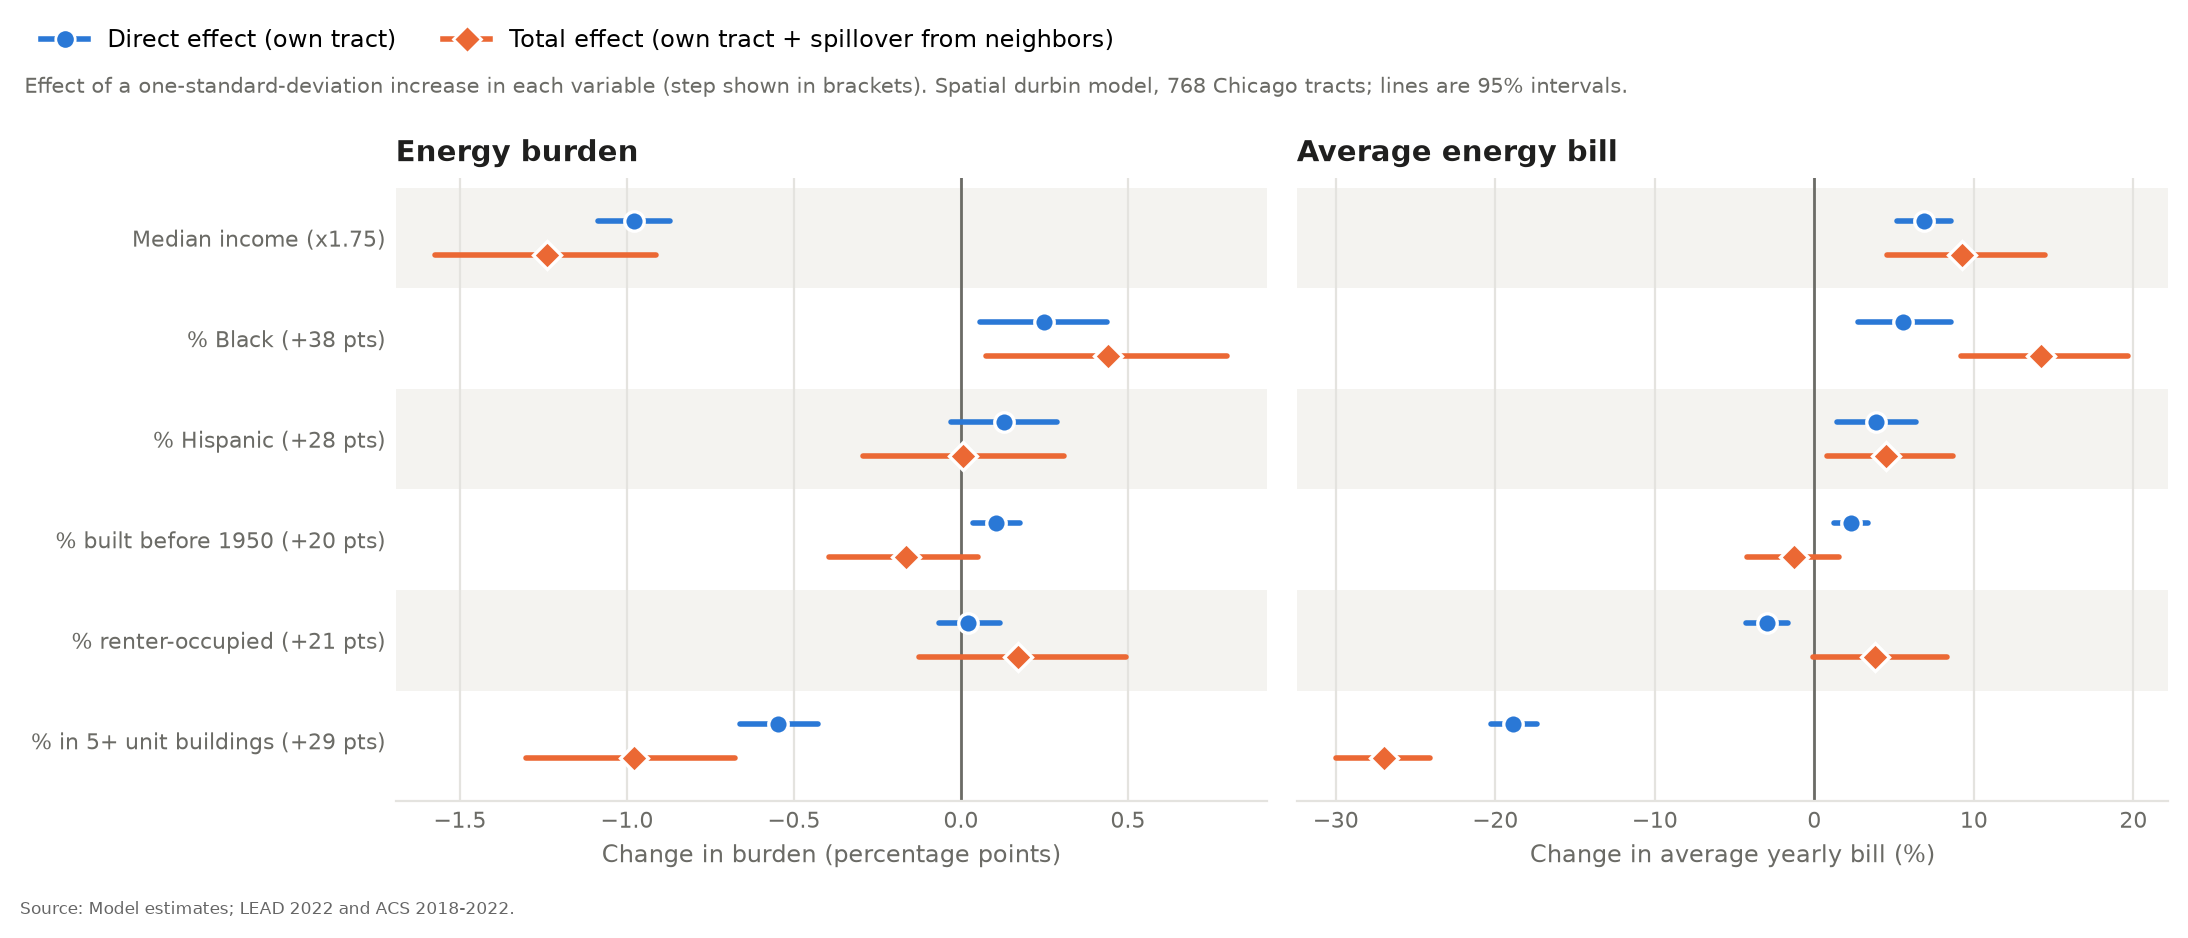

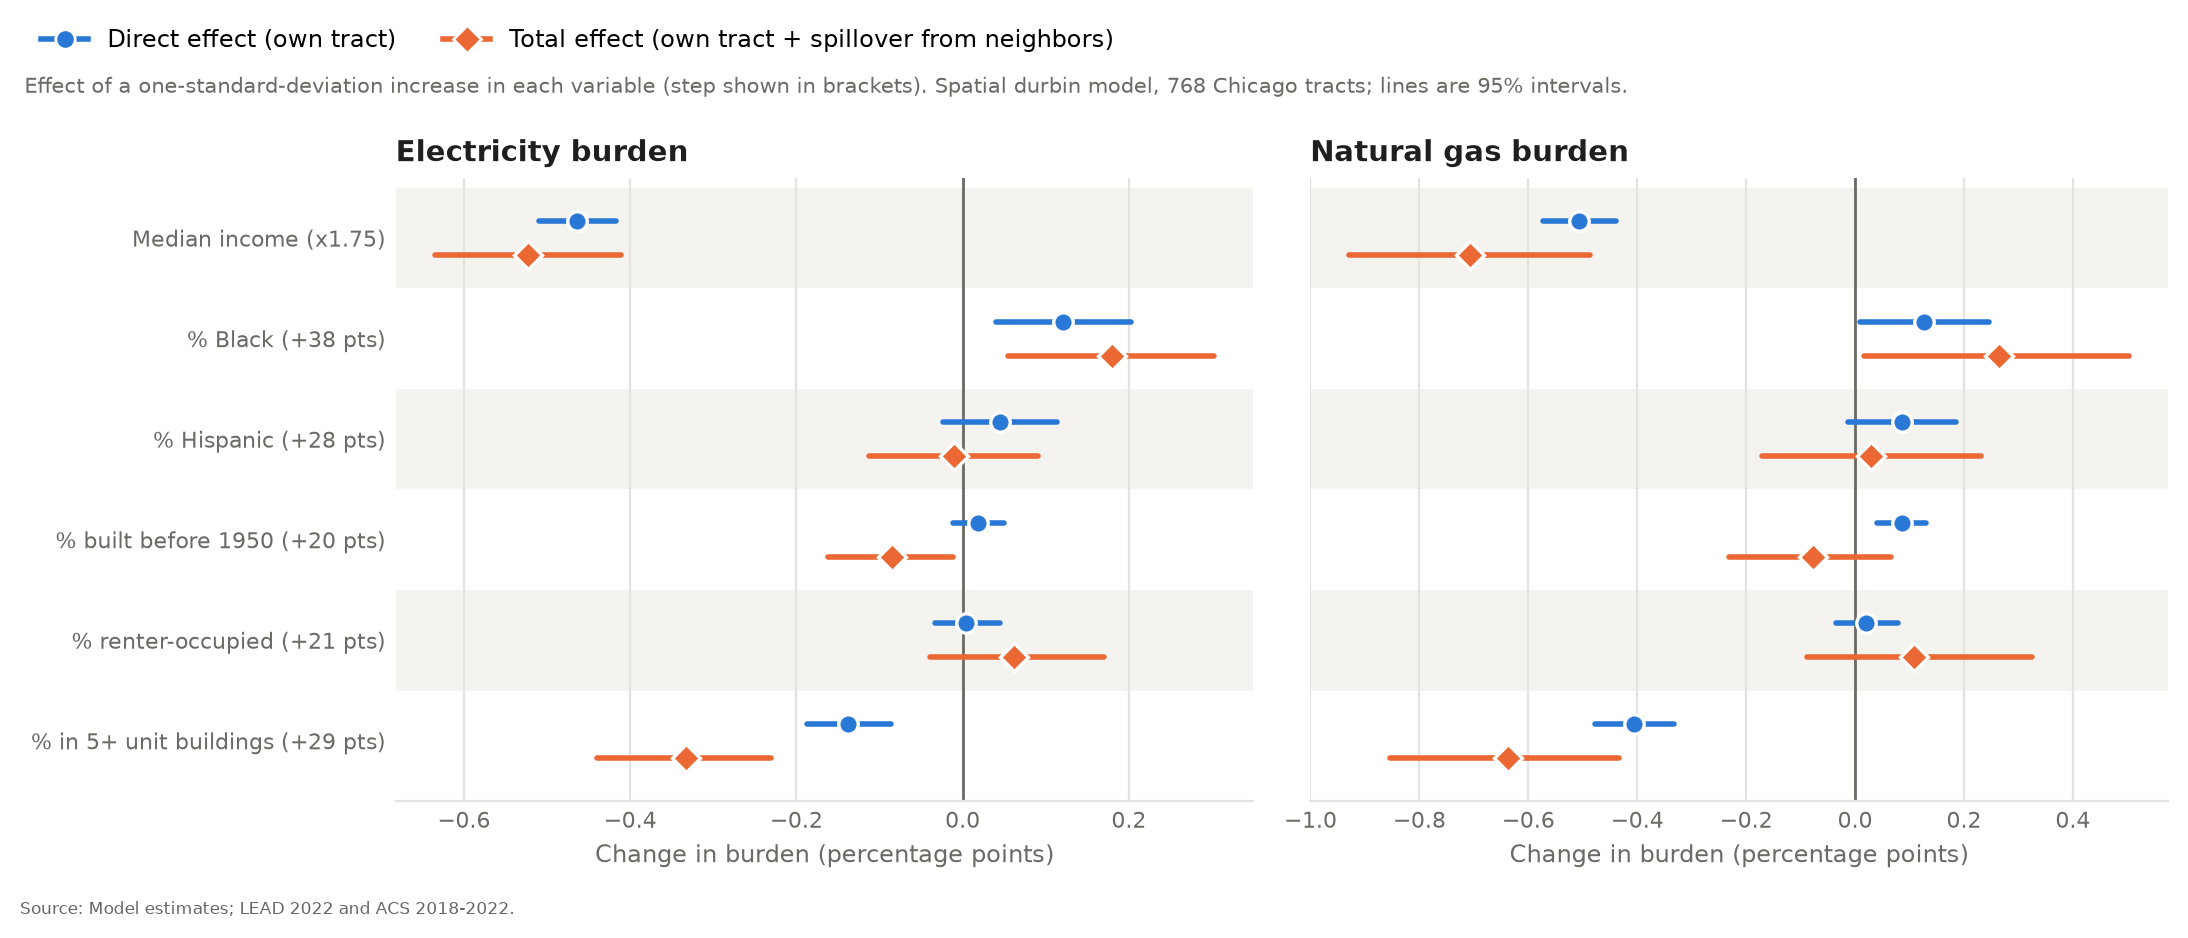

In [6]:
display(Image(F / "effects_burden_costs.png", width=900)); display(Image(F / "effects_fuels.png", width=900))